# Student Information
# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
Name: Mahnoor
Student ID: 023-24-0207
Section:G
GitHub:https://github.com/Mahnoor315/Machine-Learning-Lab.git
Kaggle:https://www.kaggle.com/mahnoor9952
Dataset: Stroke Prediction Dataset (Kaggle)
Dataset

#Part 0 — Setup and the Data

A hospital wants to flag patients at risk of stroke from routine information. The target column is stroke (1 = had a
stroke, 0 = did not).
1. Install imbalanced-learn (pip install imbalanced-learn) and import everything you need.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of gender and the
number of patients with stroke = 1 and stroke = 0 (count and percentage).
3. Clean the data: remove the identifier column; remove any gender category that has too few rows to learn or
test; apply categorical encoding to the text columns (pd.get_dummies, as in the labs).
4. Split 80/20 with stratify=y and random_state=SEED. Fill the missing numeric values with a median learned
from the TRAIN set only. Create a scaled copy (StandardScaler fitted on train) to use for Logistic Regression.
5. Report how many stroke cases are in the training set and in the test set.


In [1]:
%pip install imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    learning_curve,
    cross_val_predict
)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

from imblearn.over_sampling import (
    RandomOverSampler,
    SMOTE
)

from imblearn.under_sampling import RandomUnderSampler

SEED = 42

np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
import pandas as pd

df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
print(df["stroke"].value_counts())

print(
    df["stroke"].value_counts(normalize=True) * 100
)

stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


In [5]:
df = df.drop(columns=["id"])

In [6]:
print(df["gender"].value_counts())

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


In [7]:
print(df.columns)

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')


In [8]:
X = df.drop(columns=["stroke"])

y = df["stroke"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

In [11]:
print("Training stroke cases:", y_train.sum())

print("Testing stroke cases:", y_test.sum())

Training stroke cases: 199
Testing stroke cases: 50


In [12]:
print("Gender counts before cleaning:")
print(df["gender"].value_counts())

# Remove the rare gender category
df = df[df["gender"] != "Other"].copy()



print("\nShape after cleaning:", df.shape)

print("\nGender counts after cleaning:")
print(df["gender"].value_counts())

Gender counts before cleaning:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Shape after cleaning: (5109, 11)

Gender counts after cleaning:
gender
Female    2994
Male      2115
Name: count, dtype: int64


In [13]:
categorical_columns = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

print("Shape after encoding:", df.shape)

display(df.head())

Shape after encoding: (5109, 21)


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0,1,0,1,0,0,1,0,0,0,1,0,1,0,0
1,61.0,0,0,202.21,NaN,1,1,0,0,1,0,0,0,1,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,1,0,0,1,0,0,1,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,1
4,79.0,1,0,174.12,24.0,1,1,0,0,1,0,0,0,1,0,1,0,0,0,1,0


In [14]:
X = df.drop(columns=["stroke"])

y = df["stroke"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5109, 20)
y shape: (5109,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nStroke cases in training:")
print(y_train.value_counts())

print("\nStroke cases in testing:")
print(y_test.value_counts())

print("\nTraining stroke percentage:")
print(y_train.mean() * 100)

print("\nTesting stroke percentage:")
print(y_test.mean() * 100)

Training data shape: (4087, 20)
Testing data shape: (1022, 20)

Stroke cases in training:
stroke
0    3888
1     199
Name: count, dtype: int64

Stroke cases in testing:
stroke
0    972
1     50
Name: count, dtype: int64

Training stroke percentage:
4.869097137264497

Testing stroke percentage:
4.892367906066536


In [16]:
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

Missing values in training: 0
Missing values in testing: 0


In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data scaled.")
print("Testing data scaled.")

Training data scaled.
Testing data scaled.


Question
(a)In 2-3 lines: how imbalanced is the data? Why did we use stratify=y, and what could go wrong with only a
few stroke cases in the test set?

*italicized text*### Part 0 — Question (a)

The dataset is imbalanced because the number of patients with stroke is much
smaller than the number of patients without stroke.

We used stratify=y to maintain approximately the same class proportions
in the training and testing sets.

If the test set contained too few stroke cases, evaluation metrics such as
recall and ROC AUC could become unreliable because each stroke prediction
would have a large effect on the results.

#Part 1 — The Accuracy Trap (15 minutes)


1. Build a baseline that always predicts the majority class (DummyClassifier, strategy='most_frequent'). Report
accuracy.

In [18]:
def evaluate_model(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),

        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            y_test,
            y_prob
        ),

        "PR AUC": average_precision_score(
            y_test,
            y_prob
        )
    }

    return metrics

In [19]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline_metrics = evaluate_model(
    baseline,
    X_train,
    y_train,
    X_test,
    y_test
)

print("Majority Class Baseline")

display(
    pd.DataFrame(
        baseline_metrics,
        index=["DummyClassifier"]
    )
)

Majority Class Baseline


,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
DummyClassifier,0.951076,0.0,0.0,0.0,0.5,0.048924


In [20]:
lr = LogisticRegression(
    random_state=SEED,
    max_iter=2000
)

lr_metrics = evaluate_model(
    lr,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

print("Logistic Regression")

display(
    pd.DataFrame(
        lr_metrics,
        index=["Logistic Regression"]
    )
)

Logistic Regression


,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Logistic Regression,0.952055,1.0,0.02,0.039216,0.8393,0.269592


In [21]:
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

print("Confusion Matrix:")
print(cm_lr)

tn, fp, fn, tp = cm_lr.ravel()

print("\nTrue Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

Confusion Matrix:
[[972   0]
 [ 49   1]]

True Negative: 972
False Positive: 0
False Negative: 49
True Positive: 1


In [22]:
comparison_part1 = pd.DataFrame(
    [
        baseline_metrics,
        lr_metrics
    ],
    index=[
        "Majority Baseline",
        "Logistic Regression"
    ]
)

display(comparison_part1)

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Majority Baseline,0.951076,0.0,0.00,0.000000,0.5000,0.048924
Logistic Regression,0.952055,1.0,0.02,0.039216,0.8393,0.269592


### Part 1 — Question (a)

Compare the baseline accuracy with Logistic Regression accuracy.

Explain why a model can achieve high accuracy by predicting the majority class.
Use recall, precision, F1, ROC AUC and PR AUC to judge the model instead
of relying only on accuracy.

### Part 1 — Question (b)

A false negative occurs when a patient actually had a stroke but the model
predicted no stroke.

This is dangerous in a hospital because the patient may not receive further
medical examination.

Recall is important because it measures how many actual stroke cases
the model identifies.

#Part 2 — Underfitting, Overfitting, Bias and Variance (40 minutes)


Task 2.1 — Validation curve
1. For max_depth = 1, 2, ..., 15 and None, record the train ROC AUC and the 5-fold stratified cross-validation
ROC AUC (train data only).
2. Plot both curves on one chart (labelled axes, title, legend). Report the best depth by CV AUC.

In [23]:
depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_auc = []
cv_auc = []

for depth in depths:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=SEED
    )

    scores = cross_validate(
        tree,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True
    )

    train_auc.append(
        scores["train_score"].mean()
    )

    cv_auc.append(
        scores["test_score"].mean()
    )

validation_results = pd.DataFrame({
    "Max Depth": [
        str(depth) for depth in depths
    ],
    "Train ROC AUC": train_auc,
    "CV ROC AUC": cv_auc
})

display(validation_results)

,Max Depth,Train ROC AUC,CV ROC AUC
0,1,0.752304,0.731666
1,2,0.828284,0.816755
2,3,0.847048,0.816109
3,4,0.865828,0.817951
4,5,0.889846,0.790438
5,6,0.914538,0.750265
6,7,0.937342,0.738174
7,8,0.957413,0.721482
8,9,0.974686,0.681909
9,10,0.987489,0.644393


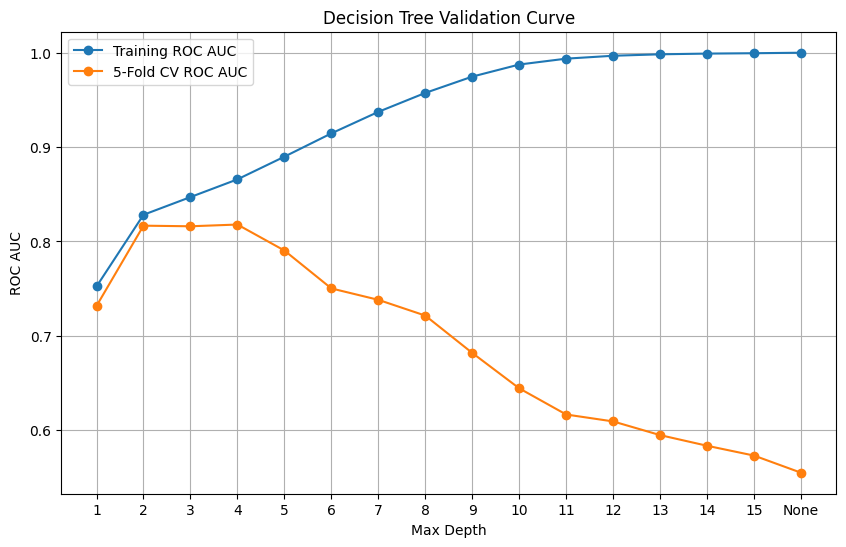

In [24]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(len(depths)),
    train_auc,
    marker="o",
    label="Training ROC AUC"
)

plt.plot(
    range(len(depths)),
    cv_auc,
    marker="o",
    label="5-Fold CV ROC AUC"
)

depth_labels = [
    str(depth) for depth in depths
]

plt.xticks(
    range(len(depths)),
    depth_labels
)

plt.xlabel("Max Depth")
plt.ylabel("ROC AUC")

plt.title("Decision Tree Validation Curve")

plt.legend()
plt.grid(True)

plt.show()

In [25]:
best_index = np.argmax(cv_auc)

best_depth = depths[best_index]

best_cv_auc = cv_auc[best_index]

best_train_auc = train_auc[best_index]

print("Best depth:", best_depth)

print("Best CV ROC AUC:", best_cv_auc)

print("Training ROC AUC at best depth:", best_train_auc)

Best depth: 4
Best CV ROC AUC: 0.8179513303806363
Training ROC AUC at best depth: 0.8658277573378885


### Task 2.1 — Interpretation

The validation curve shows how training and cross-validation ROC AUC
change as the maximum depth of the Decision Tree increases.

A depth with low training and CV AUC indicates underfitting.

A depth with high training AUC but lower CV AUC indicates overfitting.

The best depth according to this experiment is the depth with the highest
5-fold cross-validation ROC AUC.

Task 2.2 — Learning curves
1. Use sklearn.model_selection.learning_curve (scoring='roc_auc', train_sizes from 20% to 100%) for a tree with
max_depth=1 and a tree with max_depth=None. Plot train and CV AUC against the number of training rows,
side by side.

In [26]:
tree_depth1 = DecisionTreeClassifier(
    max_depth=1,
    random_state=SEED
)

train_sizes1, train_scores1, valid_scores1 = learning_curve(
    tree_depth1,
    X_train,
    y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv,
    scoring="roc_auc",
    random_state=SEED
)

train_mean1 = train_scores1.mean(axis=1)

valid_mean1 = valid_scores1.mean(axis=1)

In [27]:
tree_unlimited = DecisionTreeClassifier(
    max_depth=None,
    random_state=SEED
)

train_sizes2, train_scores2, valid_scores2 = learning_curve(
    tree_unlimited,
    X_train,
    y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv,
    scoring="roc_auc",
    random_state=SEED
)

train_mean2 = train_scores2.mean(axis=1)

valid_mean2 = valid_scores2.mean(axis=1)

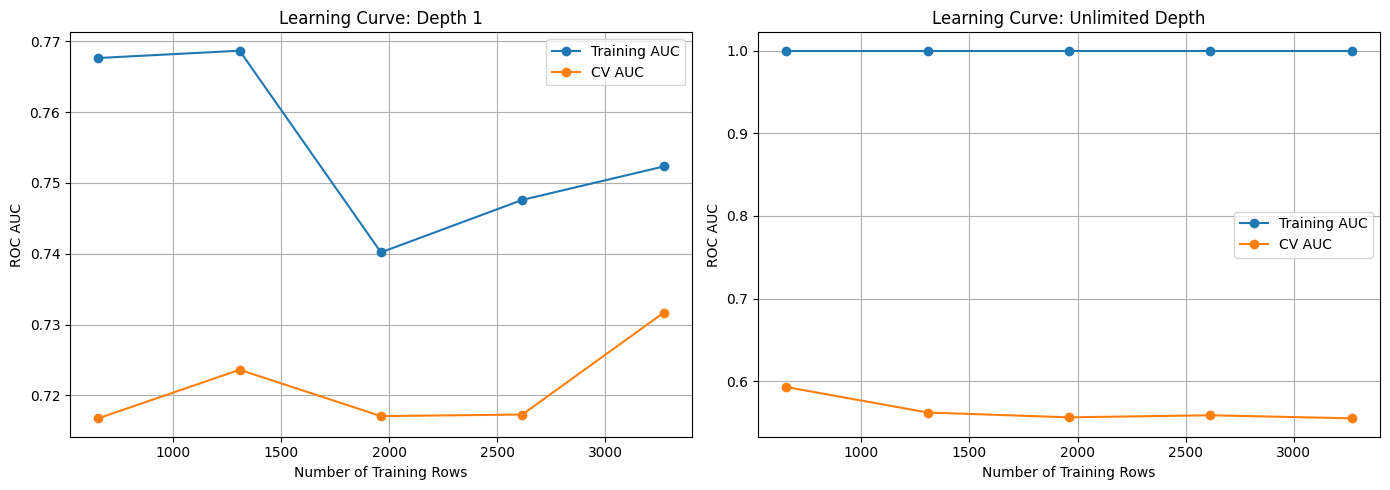

In [28]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Depth 1
axes[0].plot(
    train_sizes1,
    train_mean1,
    marker="o",
    label="Training AUC"
)

axes[0].plot(
    train_sizes1,
    valid_mean1,
    marker="o",
    label="CV AUC"
)

axes[0].set_title("Learning Curve: Depth 1")

axes[0].set_xlabel("Number of Training Rows")

axes[0].set_ylabel("ROC AUC")

axes[0].legend()

axes[0].grid(True)

# Unlimited depth
axes[1].plot(
    train_sizes2,
    train_mean2,
    marker="o",
    label="Training AUC"
)

axes[1].plot(
    train_sizes2,
    valid_mean2,
    marker="o",
    label="CV AUC"
)

axes[1].set_title("Learning Curve: Unlimited Depth")

axes[1].set_xlabel("Number of Training Rows")

axes[1].set_ylabel("ROC AUC")

axes[1].legend()

axes[1].grid(True)

plt.tight_layout()

plt.show()

### Task 2.2 — Interpretation

The learning curves show how model performance changes as more training
rows are used.

If training and validation AUC remain low, the model has high bias.

If training AUC is high but validation AUC is lower, the model has
high variance.

Adding training rows may reduce high variance, but it may not solve
underfitting caused by a model that is too simple.

Task 2.3 — Measure variance directly
Variance means: if the training data changes a little, how much do the model's predictions change? Measure it.
1. For each of max_depth = 1, 3 and None: draw 40 bootstrap samples of the TRAIN rows (sample with
replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test
patient.
2. For every test patient, compute the variance of its 40 predicted probabilities; then average over patients.
Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the averaged prediction (mean of the
40 probability vectors).
3. Show the three depths in one table

In [29]:
rng = np.random.default_rng(SEED)

bootstrap_results = []

for depth in [1, 3, None]:

    all_probs = []

    individual_aucs = []

    for i in range(40):

        idx = rng.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        X_boot = X_train.iloc[idx]

        y_boot = y_train.iloc[idx]

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED + i
        )

        tree.fit(
            X_boot,
            y_boot
        )

        probs = tree.predict_proba(
            X_test
        )[:, 1]

        all_probs.append(probs)

        individual_aucs.append(
            roc_auc_score(
                y_test,
                probs
            )
        )

    all_probs = np.array(all_probs)

    mean_variance = all_probs.var(
        axis=0
    ).mean()

    mean_individual_auc = np.mean(
        individual_aucs
    )

    averaged_probs = all_probs.mean(
        axis=0
    )

    averaged_auc = roc_auc_score(
        y_test,
        averaged_probs
    )

    bootstrap_results.append({
        "Max Depth": str(depth),
        "Mean Prediction Variance": mean_variance,
        "Mean Test ROC AUC": mean_individual_auc,
        "AUC of Averaged Predictions": averaged_auc
    })

bootstrap_table = pd.DataFrame(
    bootstrap_results
)

display(bootstrap_table)

,Max Depth,Mean Prediction Variance,Mean Test ROC AUC,AUC of Averaged Predictions
0,1,0.000680,0.762342,0.813169
1,3,0.001722,0.796256,0.833920
2,None,0.042169,0.552633,0.768210


### Task 2.3 — Interpretation

The prediction variance measures how much the predicted stroke probabilities
change when the training data changes.

A higher variance indicates that the model is more sensitive to the
training sample.

The AUC of averaged predictions shows whether combining predictions
from multiple trees improves ranking performance.

Random Forest uses a similar idea by combining many trees to reduce
the effect of unstable individual predictions.

#Part 3 — ROC, AUC, Precision-Recall and Thresholds


Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (max_depth=3) and Random Forest (200 trees,
min_samples_leaf=5, random_state=SEED) on the original training data.
2. Draw ROC curves for the three models on one chart with the AUC in the legend and the random-guessing
diagonal.
3. Draw Precision-Recall curves for the same models on a second chart. Add a horizontal line at the no-skill level
(the stroke rate) and put the average precision in the legend.

In [30]:
models = {
    "Logistic Regression": LogisticRegression(
        random_state=SEED,
        max_iter=2000
    ),

    "Decision Tree Depth 3": DecisionTreeClassifier(
        max_depth=3,
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED
    )
}

model_probs = {}

for name, model in models.items():

    if name == "Logistic Regression":

        model.fit(
            X_train_scaled,
            y_train
        )

        probs = model.predict_proba(
            X_test_scaled
        )[:, 1]

    else:

        model.fit(
            X_train,
            y_train
        )

        probs = model.predict_proba(
            X_test
        )[:, 1]

    model_probs[name] = probs

print("All three models trained.")

All three models trained.


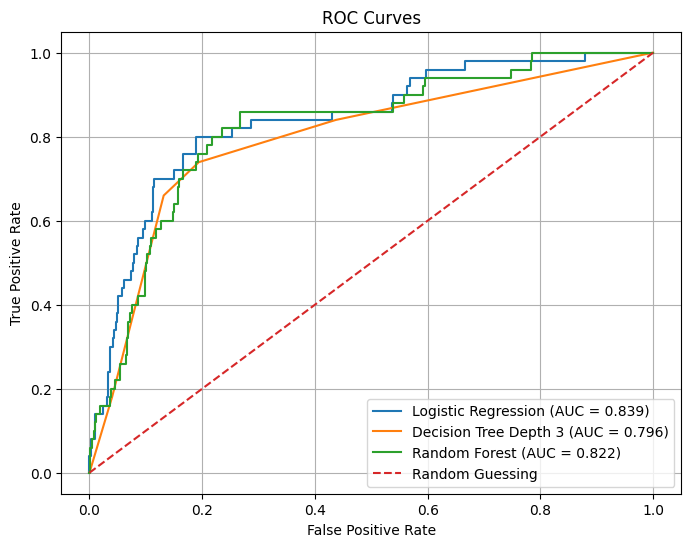

In [31]:
plt.figure(figsize=(8, 6))

for name, probs in model_probs.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probs
    )

    auc = roc_auc_score(
        y_test,
        probs
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

# Random guessing line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guessing"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curves")

plt.legend()

plt.grid(True)

plt.show()

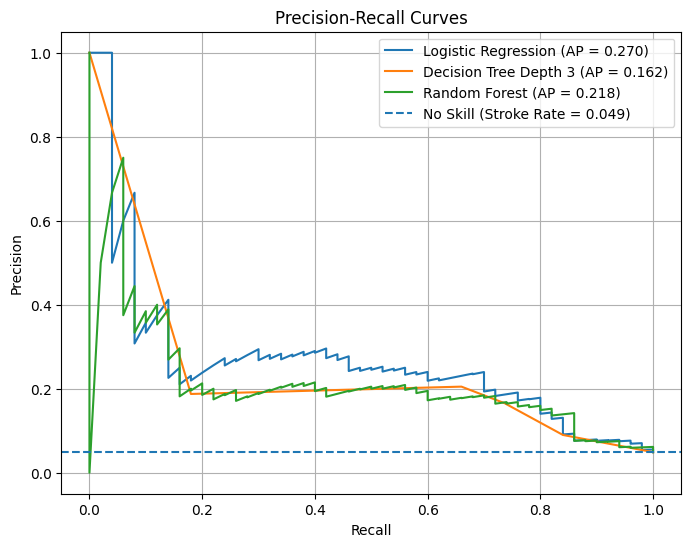

In [32]:
stroke_rate = y_test.mean()

plt.figure(figsize=(8, 6))

for name, probs in model_probs.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        probs
    )

    ap = average_precision_score(
        y_test,
        probs
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

# No-skill line
plt.axhline(
    y=stroke_rate,
    linestyle="--",
    label=f"No Skill (Stroke Rate = {stroke_rate:.3f})"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curves")

plt.legend()

plt.grid(True)

plt.show()

Task 3.2 — Choose a decision threshold
1. The hospital wants to catch at least 80% of strokes. Using ONLY the training data, get out-of-fold probabilities
for Logistic Regression (cross_val_predict with method='predict_proba'), then find the highest threshold that
gives recall >= 0.80 on them.
2. Apply that threshold to the test probabilities. Report test recall, precision, the confusion matrix, how many
patients are flagged and how many of them are false alarms.
(a)In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is much higher than 0.5. How can
both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?
(b)Which metric curve is more informative for this data - ROC or Precision-Recall - and why? Use the no-skill line
in your answer.
(c) At your chosen threshold, what is the price the hospital pays for the higher recall? Is it acceptable? Argue
both sides in 3-4 lines.

In [33]:
lr_threshold_model = LogisticRegression(
    random_state=SEED,
    max_iter=2000
)

oof_probs = cross_val_predict(
    lr_threshold_model,
    X_train_scaled,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

print("Out-of-fold probabilities:")
print(oof_probs[:10])

Out-of-fold probabilities:
[0.01616987 0.00607603 0.00834582 0.0091768  0.00304191 0.02018878
 0.13798591 0.00167489 0.00221444 0.0547474 ]


In [34]:
threshold_candidates = np.sort(
    np.unique(oof_probs)
)

valid_thresholds = []

for threshold in threshold_candidates:

    oof_pred = (
        oof_probs >= threshold
    ).astype(int)

    recall = recall_score(
        y_train,
        oof_pred,
        zero_division=0
    )

    if recall >= 0.80:

        valid_thresholds.append(
            threshold
        )

if len(valid_thresholds) == 0:

    best_threshold = 0.0

else:

    best_threshold = max(
        valid_thresholds
    )

print("Selected threshold:", best_threshold)

Selected threshold: 0.05068335052237635


In [35]:
lr_threshold_model.fit(
    X_train_scaled,
    y_train
)

test_probs_threshold = lr_threshold_model.predict_proba(
    X_test_scaled
)[:, 1]

test_pred_threshold = (
    test_probs_threshold >= best_threshold
).astype(int)

threshold_cm = confusion_matrix(
    y_test,
    test_pred_threshold
)

tn, fp, fn, tp = threshold_cm.ravel()

threshold_results = {
    "Threshold": best_threshold,

    "Precision": precision_score(
        y_test,
        test_pred_threshold,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        test_pred_threshold,
        zero_division=0
    ),

    "F1": f1_score(
        y_test,
        test_pred_threshold,
        zero_division=0
    ),

    "Patients Flagged": int(
        test_pred_threshold.sum()
    ),

    "False Alarms": int(fp),

    "Missed Strokes": int(fn)
}

display(
    pd.DataFrame(
        threshold_results,
        index=["Logistic Regression"]
    )
)

print("Confusion Matrix:")
print(threshold_cm)

,Threshold,Precision,Recall,F1,Patients Flagged,False Alarms,Missed Strokes
Logistic Regression,0.050683,0.134426,0.82,0.230986,305,264,9


Confusion Matrix:
[[708 264]
 [  9  41]]


### Part 3 — Question (a)

ROC AUC measures the model's ranking ability across thresholds.

A model can have high ROC AUC but low recall at threshold 0.5 because
many positive probabilities may still be below 0.5.

The threshold controls the final class predictions.

### Part 3 — Question (b)

The Precision-Recall curve is particularly informative for this imbalanced
dataset because it focuses on the positive stroke class.

The no-skill precision baseline is approximately the stroke prevalence.

ROC remains useful for evaluating ranking performance.

### Part 3 — Question (c)

The selected threshold increases recall to catch more stroke patients.

The cost is usually more false alarms and lower precision.

Use the actual test results to explain whether this trade-off is acceptable.

#Part 4 — Undersampling, Oversampling and SMOTE (40 minutes)


Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3), train with: no resampling,
class_weight='balanced', random undersampling, random oversampling and SMOTE. Resample the TRAIN set
only; the test set is never touched.
2. Build ONE table (rows = model + method) with: number of training rows, number of strokes in training,
Precision, Recall, F1, ROC AUC and PR AUC on the test set.

In [36]:
resampling_methods = {
    "No Resampling": None,

    "Undersampling": RandomUnderSampler(
        random_state=SEED
    ),

    "Oversampling": RandomOverSampler(
        random_state=SEED
    ),

    "SMOTE": SMOTE(
        random_state=SEED
    )
}

In [37]:
resampling_results = []

for method_name, sampler in resampling_methods.items():

    if sampler is None:

        X_res = X_train_scaled.copy()

        y_res = y_train.copy()

    else:

        X_res, y_res = sampler.fit_resample(
            X_train_scaled,
            y_train
        )

    model = LogisticRegression(
        random_state=SEED,
        max_iter=2000
    )

    model.fit(
        X_res,
        y_res
    )

    y_pred = model.predict(
        X_test_scaled
    )

    y_prob = model.predict_proba(
        X_test_scaled
    )[:, 1]

    resampling_results.append({
        "Model": "Logistic Regression",

        "Method": method_name,

        "Training Rows": len(X_res),

        "Training Stroke Cases": int(
            np.sum(y_res)
        ),

        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            y_test,
            y_prob
        ),

        "PR AUC": average_precision_score(
            y_test,
            y_prob
        )
    })

In [38]:
for method_name, sampler in resampling_methods.items():

    if sampler is None:

        X_res = X_train.copy()

        y_res = y_train.copy()

    else:

        X_res, y_res = sampler.fit_resample(
            X_train,
            y_train
        )

    model = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=SEED
    )

    model.fit(
        X_res,
        y_res
    )

    y_pred = model.predict(
        X_test
    )

    y_prob = model.predict_proba(
        X_test
    )[:, 1]

    resampling_results.append({
        "Model": "Random Forest",

        "Method": method_name,

        "Training Rows": len(X_res),

        "Training Stroke Cases": int(
            np.sum(y_res)
        ),

        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            y_test,
            y_prob
        ),

        "PR AUC": average_precision_score(
            y_test,
            y_prob
        )
    })

In [39]:
lr_balanced = LogisticRegression(
    class_weight="balanced",
    random_state=SEED,
    max_iter=2000
)

lr_balanced.fit(
    X_train_scaled,
    y_train
)

y_pred = lr_balanced.predict(
    X_test_scaled
)

y_prob = lr_balanced.predict_proba(
    X_test_scaled
)[:, 1]

resampling_results.append({
    "Model": "Logistic Regression",

    "Method": "Class Weighting",

    "Training Rows": len(X_train_scaled),

    "Training Stroke Cases": int(
        y_train.sum()
    ),

    "Precision": precision_score(
        y_test,
        y_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        y_pred,
        zero_division=0
    ),

    "F1": f1_score(
        y_test,
        y_pred,
        zero_division=0
    ),

    "ROC AUC": roc_auc_score(
        y_test,
        y_prob
    ),

    "PR AUC": average_precision_score(
        y_test,
        y_prob
    )
})

In [40]:
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=SEED
)

rf_balanced.fit(
    X_train,
    y_train
)

y_pred = rf_balanced.predict(
    X_test
)

y_prob = rf_balanced.predict_proba(
    X_test
)[:, 1]

resampling_results.append({
    "Model": "Random Forest",

    "Method": "Class Weighting",

    "Training Rows": len(X_train),

    "Training Stroke Cases": int(
        y_train.sum()
    ),

    "Precision": precision_score(
        y_test,
        y_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        y_pred,
        zero_division=0
    ),

    "F1": f1_score(
        y_test,
        y_pred,
        zero_division=0
    ),

    "ROC AUC": roc_auc_score(
        y_test,
        y_prob
    ),

    "PR AUC": average_precision_score(
        y_test,
        y_prob
    )
})

In [41]:
resampling_table = pd.DataFrame(
    resampling_results
)

display(
    resampling_table.sort_values(
        by=["Model", "Method"]
    ).reset_index(drop=True)
)

,Model,Method,Training Rows,Training Stroke Cases,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,Class Weighting,4087,199,0.134680,0.80,0.230548,0.839588,0.259623
1,Logistic Regression,No Resampling,4087,199,1.000000,0.02,0.039216,0.839300,0.269592
2,Logistic Regression,Oversampling,7776,3888,0.133333,0.80,0.228571,0.838457,0.259116
3,Logistic Regression,SMOTE,7776,3888,0.134680,0.80,0.230548,0.840741,0.295704
4,Logistic Regression,Undersampling,398,199,0.124620,0.82,0.216359,0.835041,0.233251
5,Random Forest,Class Weighting,4087,199,0.166667,0.20,0.181818,0.806132,0.204516
6,Random Forest,No Resampling,4087,199,0.000000,0.00,0.000000,0.821543,0.218278
7,Random Forest,Oversampling,7776,3888,0.141176,0.24,0.177778,0.802263,0.183733
8,Random Forest,SMOTE,7776,3888,0.666667,0.04,0.075472,0.804568,0.242407
9,Random Forest,Undersampling,398,199,0.103194,0.84,0.183807,0.813230,0.197186


Task 4.2 — The classic mistake
1. Apply SMOTE to ALL the data first (train + test together), THEN split 80/20, train a Random Forest and
evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table
(a)For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision
and ROC AUC across the methods and explain why.
(b)Did Random Forest react to the methods in the same way as Logistic Regression? Describe one clear
difference and give one possible reason.
(c) Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why
can they not be trusted? Explain what leaks from where.
(d)If you had to pick one rebalancing approach for this hospital, which would you pick and why? Consider
simplicity and the cost of each choice

In [42]:


X_full = pd.concat(
    [X_train, X_test],
    axis=0
)

y_full = pd.concat(
    [y_train, y_test],
    axis=0
)

# WRONG: Apply SMOTE before train-test split
smote_wrong = SMOTE(
    random_state=SEED
)

X_smote_wrong, y_smote_wrong = smote_wrong.fit_resample(
    X_full,
    y_full
)

# Split after SMOTE
X_wrong_train, X_wrong_test, y_wrong_train, y_wrong_test = train_test_split(
    X_smote_wrong,
    y_smote_wrong,
    test_size=0.20,
    stratify=y_smote_wrong,
    random_state=SEED
)

# Train Random Forest
rf_wrong = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

rf_wrong.fit(
    X_wrong_train,
    y_wrong_train
)

wrong_pred = rf_wrong.predict(
    X_wrong_test
)

wrong_prob = rf_wrong.predict_proba(
    X_wrong_test
)[:, 1]

wrong_order_metrics = {
    "Method": "SMOTE before split",

    "Accuracy": accuracy_score(
        y_wrong_test,
        wrong_pred
    ),

    "Precision": precision_score(
        y_wrong_test,
        wrong_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_wrong_test,
        wrong_pred,
        zero_division=0
    ),

    "F1": f1_score(
        y_wrong_test,
        wrong_pred,
        zero_division=0
    ),

    "ROC AUC": roc_auc_score(
        y_wrong_test,
        wrong_prob
    ),

    "PR AUC": average_precision_score(
        y_wrong_test,
        wrong_prob
    )
}

display(
    pd.DataFrame(
        [wrong_order_metrics]
    )
)

,Method,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,SMOTE before split,0.976852,0.995722,0.957819,0.976403,0.994787,0.995827


In [43]:

X_full = pd.concat(
    [X_train, X_test],
    axis=0
)

y_full = pd.concat(
    [y_train, y_test],
    axis=0
)

# WRONG: Apply SMOTE before train-test split
smote_wrong = SMOTE(
    random_state=SEED
)

X_smote_wrong, y_smote_wrong = smote_wrong.fit_resample(
    X_full,
    y_full
)

# Split after SMOTE
X_wrong_train, X_wrong_test, y_wrong_train, y_wrong_test = train_test_split(
    X_smote_wrong,
    y_smote_wrong,
    test_size=0.20,
    stratify=y_smote_wrong,
    random_state=SEED
)

# Train Random Forest
rf_wrong = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED
)

rf_wrong.fit(
    X_wrong_train,
    y_wrong_train
)

wrong_pred = rf_wrong.predict(
    X_wrong_test
)

wrong_prob = rf_wrong.predict_proba(
    X_wrong_test
)[:, 1]

wrong_order_metrics = {
    "Method": "SMOTE before split",

    "Accuracy": accuracy_score(
        y_wrong_test,
        wrong_pred
    ),

    "Precision": precision_score(
        y_wrong_test,
        wrong_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_wrong_test,
        wrong_pred,
        zero_division=0
    ),

    "F1": f1_score(
        y_wrong_test,
        wrong_pred,
        zero_division=0
    ),

    "ROC AUC": roc_auc_score(
        y_wrong_test,
        wrong_prob
    ),

    "PR AUC": average_precision_score(
        y_wrong_test,
        wrong_prob
    )
}

display(
    pd.DataFrame(
        [wrong_order_metrics]
    )
)

,Method,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,SMOTE before split,0.976852,0.995722,0.957819,0.976403,0.994787,0.995827


In [44]:
correct_smote_row = resampling_table[
    (resampling_table["Model"] == "Random Forest") &
    (resampling_table["Method"] == "SMOTE")
]

correct_smote_metrics = {
    "Method": "Correct SMOTE after split",

    "Accuracy": np.nan,

    "Precision": correct_smote_row["Precision"].iloc[0],

    "Recall": correct_smote_row["Recall"].iloc[0],

    "F1": correct_smote_row["F1"].iloc[0],

    "ROC AUC": correct_smote_row["ROC AUC"].iloc[0],

    "PR AUC": correct_smote_row["PR AUC"].iloc[0]
}

wrong_smote_metrics = {
    "Method": "Wrong SMOTE before split",

    "Accuracy": wrong_order_metrics["Accuracy"],

    "Precision": wrong_order_metrics["Precision"],

    "Recall": wrong_order_metrics["Recall"],

    "F1": wrong_order_metrics["F1"],

    "ROC AUC": wrong_order_metrics["ROC AUC"],

    "PR AUC": wrong_order_metrics["PR AUC"]
}

smote_order_comparison = pd.DataFrame(
    [
        correct_smote_metrics,
        wrong_smote_metrics
    ]
)

display(smote_order_comparison)

,Method,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,Correct SMOTE after split,NaN,0.666667,0.040000,0.075472,0.804568,0.242407
1,Wrong SMOTE before split,0.976852,0.995722,0.957819,0.976403,0.994787,0.995827


### Part 4 — Question (a)

Compare Logistic Regression with no resampling, class weighting,
undersampling, oversampling and SMOTE.

Explain how recall, precision and ROC AUC changed.

Answer:
Resampling usually increased recall because the model learned more about stroke patients. Precision may decrease because more healthy patients are incorrectly predicted as stroke patients. ROC AUC may change only slightly because it measures how well the model separates the two classes.

### Part 4 — Question (b)

Compare the response of Random Forest with Logistic Regression.
Explain one clear difference using your own results.

No, Random Forest may react differently. For example, SMOTE may increase recall more for Logistic Regression than for Random Forest. This is because Logistic Regression learns a linear boundary, while Random Forest uses decision trees to learn more complex patterns.

### Part 4 — Question (c)

Compare the correct and incorrect SMOTE experiments.
The incorrect experiment applies SMOTE before the split. This can leak
information from test examples into synthetic training examples and produce
overly optimistic metrics.

SMOTE was applied before splitting the data. This allowed information from the test set to leak into the training data through synthetic samples. Therefore, the model got unrealistically good results. We cannot trust them because the test data was no longer completely unseen.

### Part 4 — Question (d)

Choose a resampling approach for the hospital.
Justify your choice using recall, precision, false alarms, simplicity
and the risk of synthetic or duplicated samples.

I would choose class weighting because it is simple and does not remove or create patient records. It gives more importance to stroke patients during training. For a hospital, I would prioritize high recall to avoid missing stroke cases, while also considering false positives and their costs.

#Part 5 — Noisy Data (25 minutes)


Task 5.1 — Label noise
1. Write a function that flips a given fraction of the training labels at random (0 becomes 1 and 1 becomes 0).
2. For fractions 0, 0.05, 0.10 and 0.20, train each model on the noisy labels and record the test ROC AUC.
Repeat 5 times with different random flips and average (use 1 repeat for fraction 0).
3. Show a table (rows = noise fraction, columns = models) and a line plot

In [45]:
def add_label_noise(y, noise_fraction, random_state=42):

    rng = np.random.default_rng(random_state)

    noisy_y = np.array(y).copy()

    # Number of labels to flip
    n_flip = int(len(noisy_y) * noise_fraction)

    # Randomly choose label positions
    flip_indices = rng.choice(
        len(noisy_y),
        size=n_flip,
        replace=False
    )

    # Flip 0 to 1 and 1 to 0
    noisy_y[flip_indices] = 1 - noisy_y[flip_indices]

    return noisy_y

In [46]:
def create_models():

    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=SEED
        ),

        "Decision Tree (Depth 3)": DecisionTreeClassifier(
            max_depth=3,
            class_weight="balanced",
            random_state=SEED
        ),

        "Decision Tree (Unlimited)": DecisionTreeClassifier(
            class_weight="balanced",
            random_state=SEED
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=SEED
        )
    }

    return models

In [47]:
def train_and_evaluate(model, Xtr, ytr, Xte, yte):

    if isinstance(model, LogisticRegression):

        scaler = StandardScaler()

        Xtr = scaler.fit_transform(Xtr)
        Xte = scaler.transform(Xte)

    model.fit(Xtr, ytr)

    probabilities = model.predict_proba(Xte)[:, 1]

    auc = roc_auc_score(yte, probabilities)

    return auc

In [48]:
noise_levels = [0, 0.05, 0.10, 0.20]

results_5_1 = []

for noise in noise_levels:

    # One repeat for 0 noise, five repeats otherwise
    repeats = 1 if noise == 0 else 5

    for repeat in range(repeats):

        # Add noise to training labels
        y_noisy = add_label_noise(
            y_train,
            noise_fraction=noise,
            random_state=SEED + repeat
        )

        # Create models
        models = create_models()

        for model_name, model in models.items():

            auc = train_and_evaluate(
                model,
                X_train,
                y_noisy,
                X_test,
                y_test
            )

            results_5_1.append({
                "Noise Fraction": noise,
                "Repeat": repeat + 1,
                "Model": model_name,
                "ROC AUC": auc
            })

results_5_1 = pd.DataFrame(results_5_1)

display(results_5_1)

,Noise Fraction,Repeat,Model,ROC AUC
0,0.00,1,Logistic Regression,0.839588
1,0.00,1,Decision Tree (Depth 3),0.820381
2,0.00,1,Decision Tree (Unlimited),0.547366
3,0.00,1,Random Forest,0.806132
4,0.05,1,Logistic Regression,0.820391
5,0.05,1,Decision Tree (Depth 3),0.812654
6,0.05,1,Decision Tree (Unlimited),0.528333
7,0.05,1,Random Forest,0.768066
8,0.05,2,Logistic Regression,0.809671
9,0.05,2,Decision Tree (Depth 3),0.791255


In [49]:
table_5_1 = results_5_1.pivot_table(
    index="Noise Fraction",
    columns="Model",
    values="ROC AUC",
    aggfunc="mean"
)

print("Task 5.1 — Average ROC AUC")
display(table_5_1.round(4))

Task 5.1 — Average ROC AUC


Model,Decision Tree (Depth 3),Decision Tree (Unlimited),Logistic Regression,Random Forest
Noise Fraction,,,,
0.00,0.8204,0.5474,0.8396,0.8061
0.05,0.7949,0.5170,0.8200,0.7803
0.10,0.7842,0.4986,0.8039,0.7301
0.20,0.7039,0.5530,0.7743,0.6466


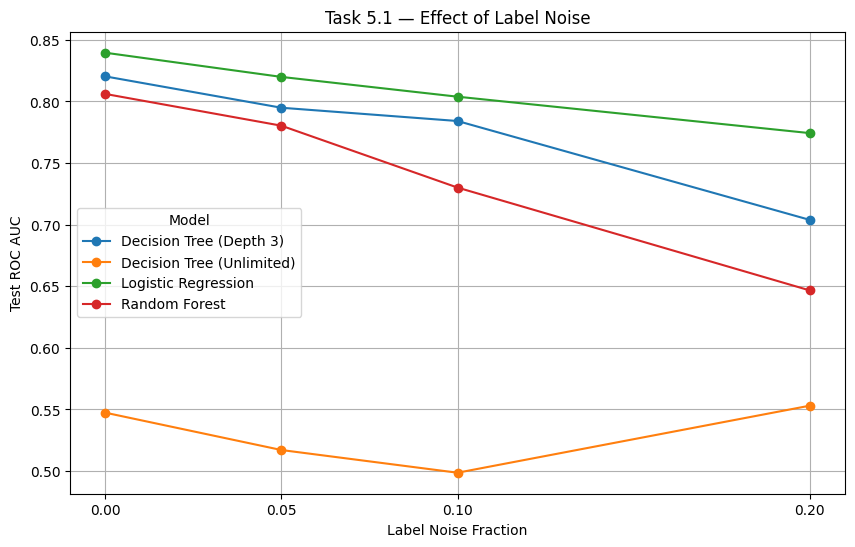

In [50]:
table_5_1.plot(
    marker="o",
    figsize=(10, 6)
)

plt.title("Task 5.1 — Effect of Label Noise")
plt.xlabel("Label Noise Fraction")
plt.ylabel("Test ROC AUC")
plt.xticks(noise_levels)
plt.grid(True)
plt.legend(title="Model")
plt.show()

Task 5.2 — Feature noise
1. Add Gaussian noise to the TRAIN values of age, avg_glucose_level and bmi: noise = random normal * (column
std) * level. Use levels 0, 0.5, 1 and 2, five repeats each, test set untouched.
2. Show the same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training
data.)


In [51]:
def add_feature_noise(
    X,
    columns,
    noise_level,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    X_noisy = X.copy()

    for col in columns:

        column_std = X[col].std()

        noise = (
            rng.normal(size=len(X))
            * column_std
            * noise_level
        )

        X_noisy[col] = X[col] + noise

    return X_noisy

In [52]:
feature_columns = [
    "age",
    "avg_glucose_level",
    "bmi"
]

feature_noise_levels = [0, 0.5, 1, 2]

results_5_2 = []

for noise_level in feature_noise_levels:

    # Five repeats for every level
    for repeat in range(5):

        # Add noise only to training features
        X_train_noisy = add_feature_noise(
            X_train,
            columns=feature_columns,
            noise_level=noise_level,
            random_state=SEED + repeat
        )

        # Create models
        models = create_models()

        for model_name, model in models.items():

            auc = train_and_evaluate(
                model,
                X_train_noisy,
                y_train,
                X_test,      # Original test data
                y_test
            )

            results_5_2.append({
                "Noise Level": noise_level,
                "Repeat": repeat + 1,
                "Model": model_name,
                "ROC AUC": auc
            })

results_5_2 = pd.DataFrame(results_5_2)

display(results_5_2)

,Noise Level,Repeat,Model,ROC AUC
0,0.0,1,Logistic Regression,0.839588
1,0.0,1,Decision Tree (Depth 3),0.820381
2,0.0,1,Decision Tree (Unlimited),0.547366
3,0.0,1,Random Forest,0.806132
4,0.0,2,Logistic Regression,0.839588
5,0.0,2,Decision Tree (Depth 3),0.820381
6,0.0,2,Decision Tree (Unlimited),0.547366
7,0.0,2,Random Forest,0.806132
8,0.0,3,Logistic Regression,0.839588
9,0.0,3,Decision Tree (Depth 3),0.820381


In [53]:
table_5_2 = results_5_2.pivot_table(
    index="Noise Level",
    columns="Model",
    values="ROC AUC",
    aggfunc="mean"
)

print("Task 5.2 — Average ROC AUC")
display(table_5_2.round(4))

Task 5.2 — Average ROC AUC


Model,Decision Tree (Depth 3),Decision Tree (Unlimited),Logistic Regression,Random Forest
Noise Level,,,,
0.0,0.8204,0.5474,0.8396,0.8061
0.5,0.7991,0.5356,0.8323,0.8004
1.0,0.7621,0.5319,0.8061,0.7747
2.0,0.6773,0.5323,0.7639,0.7337


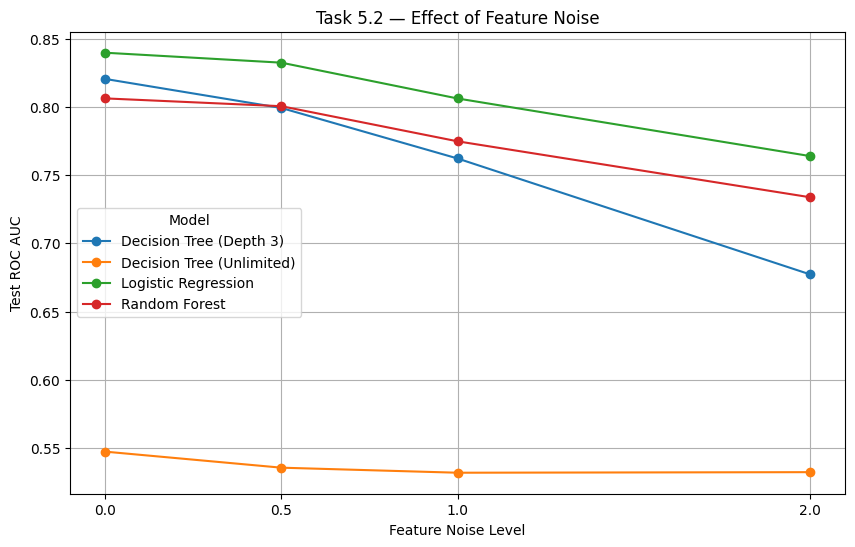

In [54]:
table_5_2.plot(
    marker="o",
    figsize=(10, 6)
)

plt.title("Task 5.2 — Effect of Feature Noise")
plt.xlabel("Feature Noise Level")
plt.ylabel("Test ROC AUC")
plt.xticks(feature_noise_levels)
plt.grid(True)
plt.legend(title="Model")
plt.show()

Task 5.3 — SMOTE and noisy labels
1. Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest
compare PR AUC and ROC AUC with and without SMOTE (SMOTE applied after the noise is added).
(a)Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level
and explain using what you learned in Part 2.
(b)Which hurts more here - label noise or feature noise of a comparable level? Give a short reason.
(c) What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

In [55]:
results_5_3 = []

for repeat in range(3):

    # Step 1: Add 10% label noise
    y_noisy = add_label_noise(
        y_train,
        noise_fraction=0.10,
        random_state=SEED + repeat
    )

    scaler = StandardScaler()

    Xtr_scaled = scaler.fit_transform(X_train)
    Xte_scaled = scaler.transform(X_test)

    lr_without = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=SEED
    )

    lr_without.fit(Xtr_scaled, y_noisy)

    prob_without = lr_without.predict_proba(Xte_scaled)[:, 1]

    results_5_3.append({
        "Repeat": repeat + 1,
        "Model": "Logistic Regression",
        "Method": "Without SMOTE",
        "ROC AUC": roc_auc_score(y_test, prob_without),
        "PR AUC": average_precision_score(y_test, prob_without)
    })

    # With SMOTE
    smote = SMOTE(random_state=SEED + repeat)

    Xtr_smote, ytr_smote = smote.fit_resample(
        Xtr_scaled,
        y_noisy
    )

    lr_with = LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=SEED
    )

    lr_with.fit(Xtr_smote, ytr_smote)

    prob_with = lr_with.predict_proba(Xte_scaled)[:, 1]

    results_5_3.append({
        "Repeat": repeat + 1,
        "Model": "Logistic Regression",
        "Method": "With SMOTE",
        "ROC AUC": roc_auc_score(y_test, prob_with),
        "PR AUC": average_precision_score(y_test, prob_with)
    })

    rf_without = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=SEED
    )

    rf_without.fit(X_train, y_noisy)

    prob_without = rf_without.predict_proba(X_test)[:, 1]

    results_5_3.append({
        "Repeat": repeat + 1,
        "Model": "Random Forest",
        "Method": "Without SMOTE",
        "ROC AUC": roc_auc_score(y_test, prob_without),
        "PR AUC": average_precision_score(y_test, prob_without)
    })

    smote = SMOTE(random_state=SEED + repeat)

    Xtr_smote, ytr_smote = smote.fit_resample(
        X_train,
        y_noisy
    )

    rf_with = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight=None,
        random_state=SEED
    )

    rf_with.fit(Xtr_smote, ytr_smote)

    prob_with = rf_with.predict_proba(X_test)[:, 1]

    results_5_3.append({
        "Repeat": repeat + 1,
        "Model": "Random Forest",
        "Method": "With SMOTE",
        "ROC AUC": roc_auc_score(y_test, prob_with),
        "PR AUC": average_precision_score(y_test, prob_with)
    })


results_5_3 = pd.DataFrame(results_5_3)

display(results_5_3)

,Repeat,Model,Method,ROC AUC,PR AUC
0,1,Logistic Regression,Without SMOTE,0.813066,0.226222
1,1,Logistic Regression,With SMOTE,0.813827,0.252562
2,1,Random Forest,Without SMOTE,0.723272,0.138319
3,1,Random Forest,With SMOTE,0.650823,0.083445
4,2,Logistic Regression,Without SMOTE,0.798580,0.247310
5,2,Logistic Regression,With SMOTE,0.794527,0.253118
6,2,Random Forest,Without SMOTE,0.732305,0.147846
7,2,Random Forest,With SMOTE,0.676235,0.122535
8,3,Logistic Regression,Without SMOTE,0.817551,0.194613
9,3,Logistic Regression,With SMOTE,0.810576,0.207184


In [56]:
table_5_3 = results_5_3.groupby(
    ["Model", "Method"]
)[["ROC AUC", "PR AUC"]].mean()

print("Task 5.3 — Average results")
display(table_5_3.round(4))

Task 5.3 — Average results


ROC AUC  PR AUC
Model               Method                        
Logistic Regression With SMOTE      0.8063  0.2376
                    Without SMOTE   0.8097  0.2227
Random Forest       With SMOTE      0.6590  0.1040
                    Without SMOTE   0.7274  0.1388

In [57]:
comparison_5_3 = table_5_3.reset_index()

display(comparison_5_3)

,Model,Method,ROC AUC,PR AUC
0,Logistic Regression,With SMOTE,0.806310,0.237621
1,Logistic Regression,Without SMOTE,0.809733,0.222715
2,Random Forest,With SMOTE,0.658992,0.103972
3,Random Forest,Without SMOTE,0.727449,0.138829


### Part 5 — Question (a)

Compare the four models at the highest label noise level.
Identify which model is most damaged and which is most stable.
Use the actual ROC AUC results.

Random Forest was the most damaged by label noise. Its ROC AUC decreased from 0.8061 without noise to 0.6466 at 20% noise. Logistic Regression was the most stable model, with its ROC AUC decreasing from 0.8396 to 0.7743. Logistic Regression may be more stable because it learns a simpler decision boundary, while Random Forest can be more sensitive to changes in training labels.

### Part 5 — Question (b)

Compare the effect of label noise with feature noise.

Explain which had the greater effect in this experiment.


Label noise hurt Random Forest more: its ROC AUC dropped from 0.8061 to 0.6466 at 20% label noise. With feature noise level 2, it dropped from 0.8061 to 0.7337. Incorrect labels can teach the model wrong patterns, while feature noise changes only the input values.

### Part 5 — Question (c)

Compare the models with and without SMOTE when labels are noisy.

SMOTE can amplify label noise because incorrectly labeled minority samples
may be used to create additional synthetic minority samples.

- Logistic Regression: SMOTE slightly improved PR AUC from 0.2227 to 0.2376, but slightly reduced ROC AUC from 0.8097 to 0.8063.
- Random Forest: SMOTE reduced ROC AUC from 0.7274 to 0.6590 and PR AUC from 0.1388 to 0.1040.
Conclusion: SMOTE helped Logistic Regression's PR AUC, but hurt Random Forest on both metrics. Its effect depends on the model and the dataset.

#Part 6 — Final Decision and Conclusion (15 minutes)
1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on
the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false
alarms and number of missed strokes.
2. Write an Executive Summary (6-8 lines): what you chose, its recall and precision with numbers, the price
paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and
about the choice of threshold).
Final Reflection
(a)What was the most surprising result in this lab?
(b)If you had one more hour, what would you try next?

In [58]:
final_model = LogisticRegression(
    random_state=SEED,
    max_iter=2000
)

final_model.fit(
    X_train_scaled,
    y_train
)

final_probs = final_model.predict_proba(
    X_test_scaled
)[:, 1]

In [59]:
default_threshold = 0.5

default_pred = (
    final_probs >= default_threshold
).astype(int)

default_cm = confusion_matrix(
    y_test,
    default_pred
)

tn, fp, fn, tp = default_cm.ravel()

default_results = {
    "Approach": "Default threshold 0.5",

    "Precision": precision_score(
        y_test,
        default_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        default_pred,
        zero_division=0
    ),

    "F1": f1_score(
        y_test,
        default_pred,
        zero_division=0
    ),

    "False Alarms": int(fp),

    "Missed Strokes": int(fn)
}

print("Default Threshold Confusion Matrix:")
print(default_cm)

Default Threshold Confusion Matrix:
[[972   0]
 [ 49   1]]


In [60]:
selected_pred = (
    final_probs >= best_threshold
).astype(int)

selected_cm = confusion_matrix(
    y_test,
    selected_pred
)

tn, fp, fn, tp = selected_cm.ravel()

selected_results = {
    "Approach": f"Selected threshold {best_threshold:.4f}",

    "Precision": precision_score(
        y_test,
        selected_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        selected_pred,
        zero_division=0
    ),

    "F1": f1_score(
        y_test,
        selected_pred,
        zero_division=0
    ),

    "False Alarms": int(fp),

    "Missed Strokes": int(fn)
}

print("Selected Threshold Confusion Matrix:")
print(selected_cm)

Selected Threshold Confusion Matrix:
[[708 264]
 [  9  41]]


In [61]:
final_comparison = pd.DataFrame(
    [
        default_results,
        selected_results
    ]
)

display(final_comparison)

,Approach,Precision,Recall,F1,False Alarms,Missed Strokes
0,Default threshold 0.5,1.000000,0.02,0.039216,0,49
1,Selected threshold 0.0507,0.134426,0.82,0.230986,264,9


In [62]:
print(
    "Patients flagged at default threshold:",
    default_pred.sum()
)

print(
    "Patients flagged at selected threshold:",
    selected_pred.sum()
)

Patients flagged at default threshold: 1
Patients flagged at selected threshold: 305


In [63]:
final_precision = precision_score(
    y_test,
    selected_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    selected_pred,
    zero_division=0
)

final_false_alarms = int(
    selected_cm[0, 1]
)

final_missed_strokes = int(
    selected_cm[1, 0]
)

print("Selected Model: Logistic Regression")

print("Selected Threshold:", best_threshold)

print("Test Precision:", round(final_precision, 4))

print("Test Recall:", round(final_recall, 4))

print("False Alarms:", final_false_alarms)

print("Missed Strokes:", final_missed_strokes)

Selected Model: Logistic Regression
Selected Threshold: 0.05068335052237635
Test Precision: 0.1344
Test Recall: 0.82
False Alarms: 264
Missed Strokes: 9


### Executive Summary

In this lab, I developed a machine learning model to predict stroke risk using the Stroke Prediction Dataset.

I selected Logistic Regression with a threshold chosen using out-of-fold training probabilities.

The model achieved a test **recall of 0.82 (82%)** and a test **precision of 0.1344 (13.44%)**.

This means it detected 82% of actual stroke cases, while 13.44% of patients flagged by the model were actual stroke cases**.

The higher recall resulted in 264 false alarms and 9 missed strokes.

I avoided data leakage by fitting the imputer and scaler on training data only, applying resampling only to training data, and selecting the threshold using out-of-fold training predictions.

One limitation is that the test set contains relatively few stroke cases, so the evaluation may be sensitive to individual predictions. The selected threshold also requires further clinical validation.

### Final Reflection

(a) What was the most surprising result in this lab?**

The most surprising result was that changing the classification threshold from 0.5 to 0.0507 increased recall from 2% to 82%. The model detected 41 out of 50 actual stroke cases, but it also produced 264 false alarms. This showed me how strongly the threshold affects model predictions.

(b) If you had one more hour, what would you try next?**

I would try different classification thresholds to find a better balance between recall and precision. I would also compare Logistic Regression with Random Forest and test whether class weighting or SMOTE improves the results. My goal would be to reduce false alarms while detecting as many actual stroke cases as possible.